# Classification of MNIST

Reproduces all figures and tables for the classification problem. The experiments are in `mnist_experiments.py`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

In [1]:
import os, tempfile
import numpy as np
from IPython.display import Image, display

os.environ["PREVIEW_DIR"] = tempfile.mkdtemp()   # the figure code also writes a PNG copy here, shown below
import figures
from plot_style import load_results, set_style

set_style()
RERUN = False    # True runs the experiment again; False draws the figure from the saved numbers in ../results/

def show(name):
    figures.FIGURES[name]()
    display(Image(os.path.join(os.environ["PREVIEW_DIR"], name + ".png"), width=850))


## Logistic regression, the baseline

The network without hidden layers (`mnist_baseline.json`).

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

In [2]:
import mnist_experiments as mx
if RERUN:
    mx.baseline_scan()
runs = load_results('mnist_baseline')['runs']
best = max(runs, key=lambda r: r['best_val'])
print('best validation accuracy', best['best_val'], 'gamma', best['gamma'], 'lambda', best['lam'], 'epoch', best['best_epoch'])

best validation accuracy 0.9284 gamma 0.001 lambda 1e-07 epoch 25


## Optimizers and learning rates

Figure `mnist_optimizers`, results in `mnist_optimizers.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

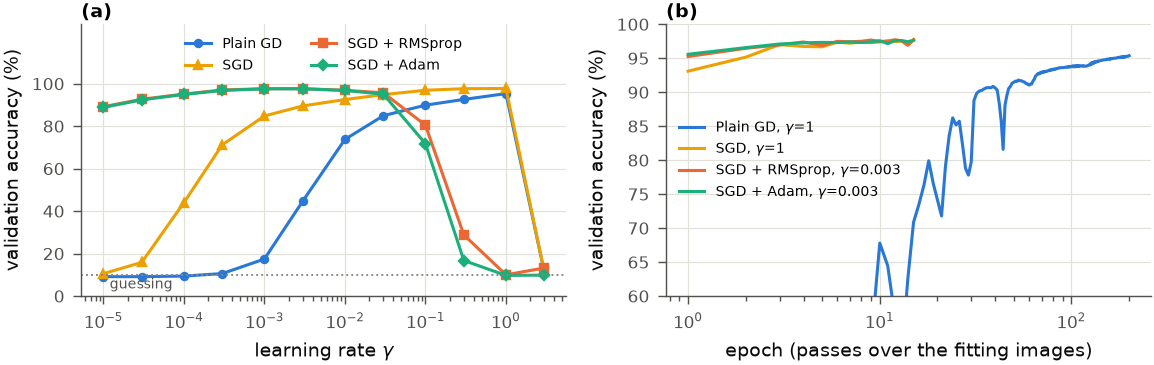

In [3]:
if RERUN:
    mx.optimizer_scan()
show('mnist_optimizers')

## Depth, width and activation

Figure `mnist_architectures`, results in `mnist_architectures.json` and `mnist_depth.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

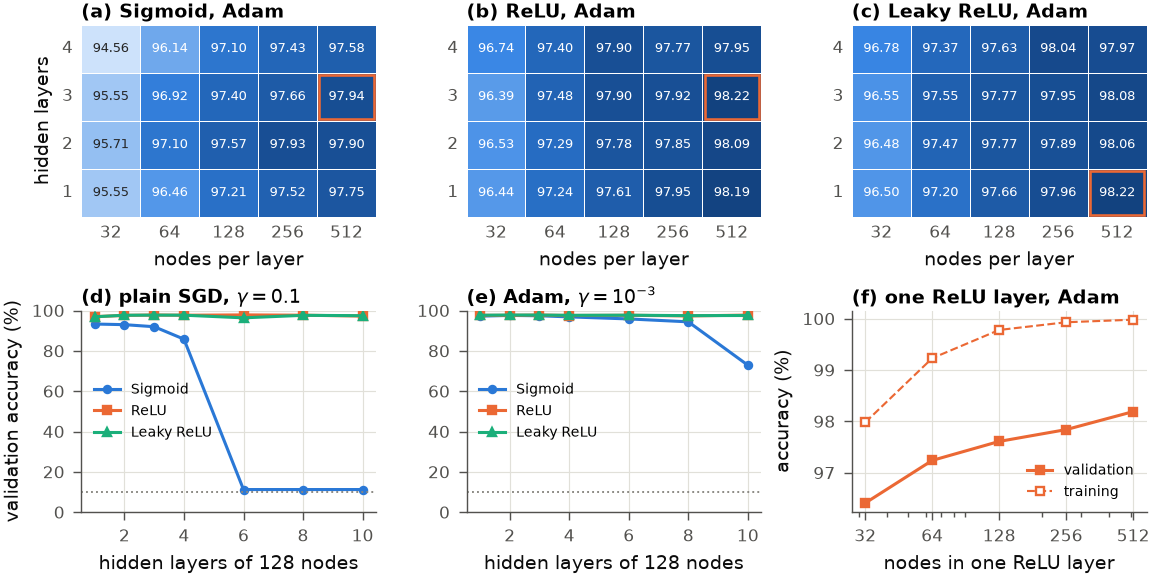

In [4]:
if RERUN:
    mx.architecture_maps(); mx.depth_study()
show('mnist_architectures')

## Scaling, initialization and matched pairs

Figure `mnist_scaling_pairs`, results in `mnist_scaling_pairs.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

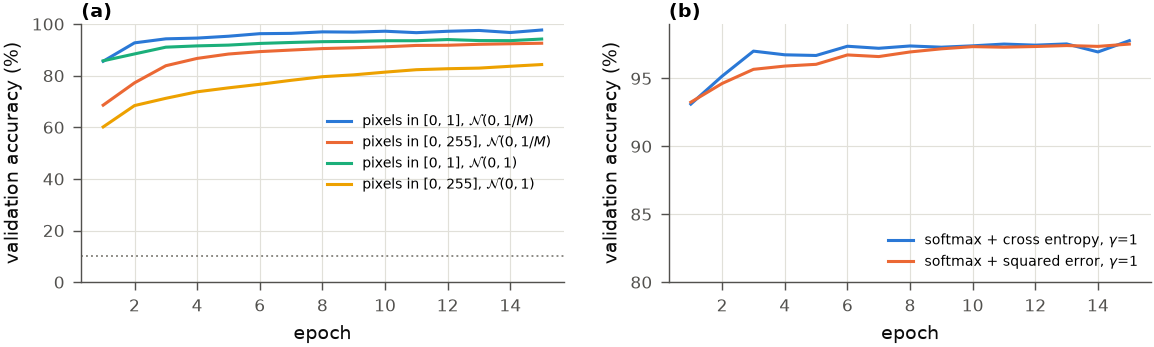

In [5]:
if RERUN:
    mx.scaling_and_pairs()
show('mnist_scaling_pairs')

## Learning rate and penalty

Figure `mnist_penalties`, results in `mnist_penalties.json`.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

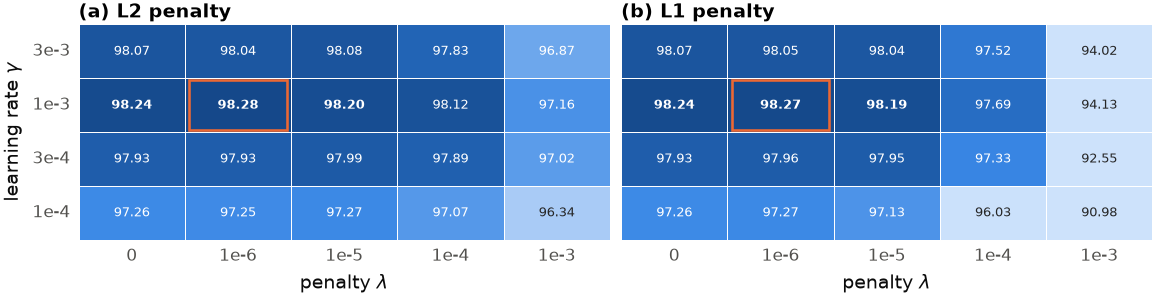

In [6]:
if RERUN:
    mx.penalty_maps()
show('mnist_penalties')

## Measurements behind the explanations

Saturation of the sigmoid layers in the scaling study, how much plain SGD and Adam change each layer of a deep sigmoid network, how confident the untrained network is, and how similar the mean images of the digits are (`mnist_mechanisms.json`). Only the fitting and validation images are used.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

In [7]:
if RERUN:
    mx.mechanisms()
m = load_results('mnist_mechanisms')
for r in m['saturation']:
    print('pixels x%g, init %s, gamma %g:' % (r['input_scale'], r['init'], r['gamma']),
          'share of saturated outputs per layer before training', np.round(r['probe'][0]['saturated'], 3),
          'and after', np.round(r['probe'][-1]['saturated'], 3))
for r in m['depth']:
    print(r['optimizer'], len(r['hidden']), 'sigmoid layers: relative change of each layer after 15 epochs',
          np.round(r['probe'][-1], 4))
print(m['initial_confidence'])
print('most similar mean digit images:', m['pair_ranking'][:5])

pixels x1, init auto, gamma 1: share of saturated outputs per layer before training [0. 0.] and after [0.225 0.005]
pixels x255, init auto, gamma 0.01: share of saturated outputs per layer before training [0.957 0.   ] and after [0.976 0.   ]
pixels x1, init unit, gamma 1: share of saturated outputs per layer before training [0.63  0.569] and after [0.698 0.715]
pixels x255, init unit, gamma 0.1: share of saturated outputs per layer before training [0.998 0.583] and after [0.999 0.752]
sgd 6 sigmoid layers: relative change of each layer after 15 epochs [0.0089 0.0039 0.0041 0.0092 0.0325 0.1375 0.0926]
sgd 10 sigmoid layers: relative change of each layer after 15 epochs [0.000e+00 0.000e+00 0.000e+00 0.000e+00 1.000e-04 5.000e-04 1.800e-03
 6.900e-03 3.010e-02 1.384e-01 8.830e-02]
adam 6 sigmoid layers: relative change of each layer after 15 epochs [4.4778 1.885  1.4554 1.3606 1.7215 1.9737 2.0566]
adam 10 sigmoid layers: relative change of each layer after 15 epochs [3.837  1.5804 1.5

## scikit-learn with ReLU nodes, on the validation images

scikit-learn has no leaky ReLU, so `library_validation` trains its network with ReLU nodes, the closest activation, next to our selected network: both on the 50 000 fitting images with the selected settings and five seeds, scored on the validation images (`mnist_library_validation.json`). The test images are not used.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

In [8]:
if RERUN:
    mx.library_validation()
v = load_results('mnist_library_validation')
for k in ('ours', 'scikit_learn_relu'):
    print(k, 'validation accuracy over five seeds:', np.round(v[k]['accuracies'], 4),
          'mean %.4f, std %.4f' % (v[k]['mean'], v[k]['std']))

ours validation accuracy over five seeds: [0.982  0.9804 0.9762 0.9811 0.9792] mean 0.9798, std 0.0022
scikit_learn_relu validation accuracy over five seeds: [0.9787 0.9799 0.9799 0.9779 0.9813] mean 0.9795, std 0.0013


## Final test, once

Figures `mnist_confusion` and `mnist_errors`, results in `mnist_final.json`. `final_evaluation` is the only function that reads the test images, and it was run once, after all choices were made. Leave `RERUN = False` unless the whole study is repeated.

> **LLM note:** the following cell only calls the modules named in it, whose own docstrings carry the `LLM-assisted` tags. The layout of this notebook and the notes above the cells were drafted with Claude Opus 5.5 (Claude Code, November 2026), code level 2, and are declared in the appendix of the report.

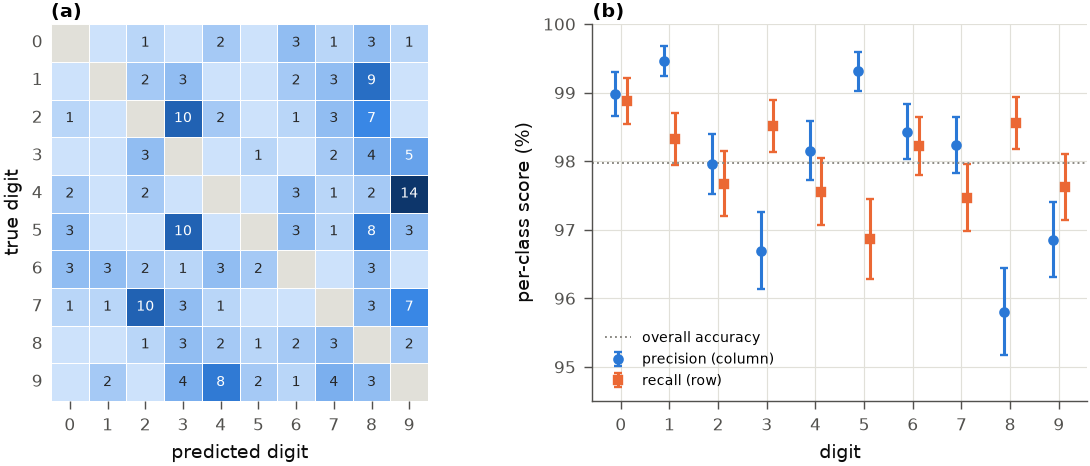

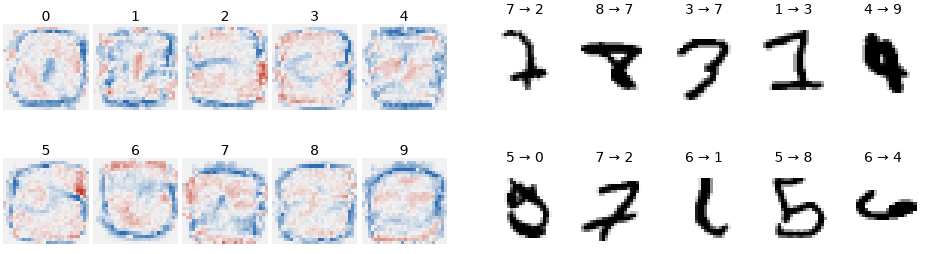

baseline test accuracy 0.9277 +- 0.0026, 8 s
network test accuracy 0.9798 +- 0.0014, 341 s
reference_100 test accuracy 0.9767 +- 0.0015, 13 s
library_logistic test accuracy 0.9257 +- 0.0026, 717 s
library_network test accuracy 0.9796 +- 0.0014, 569 s
{'network': {'hidden': [512], 'activation': 'leaky_relu', 'optimizer': 'adam', 'gamma': 0.001, 'penalty': 'l2', 'lam': 1e-05, 'batch_size': 128, 'epochs': 14}, 'baseline': {'hidden': [], 'activation': 'relu', 'optimizer': 'adam', 'gamma': 0.001, 'penalty': 'l2', 'lam': 1e-07, 'batch_size': 128, 'epochs': 25}}


In [9]:
if RERUN:
    mx.final_evaluation()
show('mnist_confusion')
show('mnist_errors')
final = load_results('mnist_final')
for k in ('baseline', 'network', 'reference_100', 'library_logistic', 'library_network'):
    print(k, 'test accuracy %.4f +- %.4f, %.0f s' % (final[k]['accuracy'], final[k]['se'], final[k]['seconds']))
print(final['settings'])